# DS5020 — A Naive Bayes Spam Classifier Built from Counts
## Iteration 2: Data Analysis and Simulation Check

*Owner: Keertana Srinivasan · Checker: Debaswini Moharana*

This notebook supports Sections 6 (Data) and 7 (Simulation Check) of our Overleaf report. It has two parts:

- **Part 1 – Real SMS data.** Load and describe the SMS Spam Collection, clean it, and check the assumptions from Section 3 of the report that can already be checked in Iteration 2.
- **Part 2 – Simulation with known truth.** Generate messages from a model whose parameters we choose (the Iteration 2 handout settings), then check each derivation (Propositions 1–5) numerically.

Every computation uses the **same symbols as the report**, and each section names the proposition, equation or assumption it checks. The proofs are in the report; this notebook only checks them with numbers.

**Libraries.** As the Iteration 2 rules require, we import only `numpy`, `pandas`, `matplotlib` and `scipy.stats`. No library routine that solves the method is used.

**How to run.** Put the original UCI file `SMSSpamCollection` in `data/` and run all cells from top to bottom. Figures are saved to `figures/`.

### Notation map: report symbol → variable in this notebook

| Report | Meaning | Variable |
|---|---|---|
| $\mathcal{C}=\{\text{ham},\text{spam}\}$, $K=2$ | classes (ham $=0$, spam $=1$) | `classes`, `K` |
| $\mathcal{V}$, $\lvert\mathcal{V}\rvert$ | vocabulary and its size | `vocabulary`, `V` |
| $X\in\mathbb{N}^{n\times\lvert\mathcal{V}\rvert}$ | count matrix, $x_{dw}$ = count of word $w$ in message $d$ | `X_train`, `X_sim` |
| $\mathbf{y}$ | labels | `y_train`, `y_sim` |
| $Y\in\{0,1\}^{n\times K}$ | one-hot label matrix (Algorithm, step 1) | `Y_onehot` |
| $n_c$ | training messages in class $c$ | `n_c` |
| $N = Y^\top X$, $N_{cw}$ | word counts per class (step 2) | `N` |
| $N_c=\sum_w N_{cw}$ | word tokens per class | `N_c` |
| $\hat\pi_c = n_c/n$ | estimated prior (Proposition 2) | `pi_hat` |
| $\hat\theta_{cw}=N_{cw}/N_c$ | MLE, unsmoothed (Proposition 2) | `theta_hat` |
| $\tilde\theta_{cw}=\dfrac{N_{cw}+\alpha}{N_c+\alpha\lvert\mathcal{V}\rvert}$ | smoothed estimate (Proposition 3) | `theta_tilde` |
| $A_{cw}=\log\tilde\theta_{cw}$, $b_c=\log\hat\pi_c$ | log parameters (step 4) | `A`, `b` |
| $S = XA^\top + \mathbf{1}\mathbf{b}^\top$ | log-scores (step 5, Proposition 4) | `S` |
| $\pi_c$, $\theta_{cw}$ (true) | parameters that generate the simulation | `pi_true`, `theta_true` |

## 1. Setting up the Python environment

Run this cell once if the packages are not installed in the environment selected by VS Code.

In [1]:
%pip install numpy pandas matplotlib scipy


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Shared functions: the algorithm of Section 5

The functions below implement steps 1–7 of the algorithm in Section 5 of the report. Writing them once means the real data, the simulation and the similarity experiment all use exactly the same formulas. Each comment gives the equation the line computes.

In [2]:
import csv
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

Path("../figures").mkdir(parents=True, exist_ok=True)
figures_dir = Path("../figures")

def one_hot(y, K):
    # Y_dc = 1 if y_d = c, else 0                      (Algorithm, step 1)
    Y = np.zeros((len(y), K), dtype=int)
    Y[np.arange(len(y)), y] = 1
    return Y


def estimate_parameters(X, y, K, alpha):
    # n_c = sum_d Y_dc,  pi_hat_c = n_c / n            (step 1, Proposition 2)
    # N = Y^T X,         N_c = sum_w N_cw              (step 2)
    # theta_hat_cw   = N_cw / N_c                      (Proposition 2, MLE)
    # theta_tilde_cw = (N_cw + alpha) / (N_c + alpha |V|)   (step 3, Proposition 3)
    Y = one_hot(y, K)
    n_c = Y.sum(axis=0)
    pi_hat = n_c / len(y)
    N = Y.T @ X
    N_c = N.sum(axis=1)
    theta_hat = N / N_c[:, None]
    V = X.shape[1]
    theta_tilde = (N + alpha) / (N_c[:, None] + alpha * V)
    return {"n_c": n_c, "pi_hat": pi_hat, "N": N, "N_c": N_c,
            "theta_hat": theta_hat, "theta_tilde": theta_tilde}


def log_scores(X, theta, pi):
    # A_cw = log theta_cw,  b_c = log pi_c             (step 4)
    # S = X A^T + 1 b^T                                (step 5, Proposition 4(c))
    A = np.log(theta)
    b = np.log(pi)
    return X @ A.T + b


def posteriors_from_scores(S):
    # Pr(c | x_i) = exp(S_ic - M_i) / sum_c' exp(S_ic' - M_i),  M_i = max_c S_ic   (step 7)
    M = S.max(axis=1, keepdims=True)
    E = np.exp(S - M)
    return E / E.sum(axis=1, keepdims=True)


def confusion_counts(y_true, y_pred, positive=1):
    # Definition 7: spam (= 1) is the positive class
    tp = int(np.sum((y_true == positive) & (y_pred == positive)))
    fp = int(np.sum((y_true != positive) & (y_pred == positive)))
    fn = int(np.sum((y_true == positive) & (y_pred != positive)))
    tn = int(np.sum((y_true != positive) & (y_pred != positive)))
    return tp, fp, fn, tn


def tokenize(message):
    # lower-case, then keep runs of letters and digits; punctuation is removed
    return re.findall(r"[a-z0-9]+", message.lower())

print("Functions ready.")

Functions ready.


# Part 1 – Real SMS Data

## 3. Load the SMS data

The UCI file is tab-separated with no header row, so we name the two columns `label` and `message`.

**Why `quoting=csv.QUOTE_NONE`.** Some messages contain the character `"`. By default pandas treats `"` as the start of a quoted field and can merge several lines into one row, so messages silently disappear. With quoting turned off, every line is exactly one message. We then compare the counts with the statistics in the dataset's own readme (5,574 messages: 4,827 ham and 747 spam).

In [3]:
possible_paths = [Path("data") / "SMSSpamCollection",
                  Path("../data") / "SMSSpamCollection",
                  Path("SMSSpamCollection")]
data_path = next((p for p in possible_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Put SMSSpamCollection in the project's data/ folder.")

sms_original = pd.read_csv(data_path, sep="\t", header=None,
                           names=["label", "message"],
                           quoting=csv.QUOTE_NONE, encoding="utf-8")

with open(data_path, encoding="utf-8") as f:
    n_lines = sum(1 for line in f if line.strip())

print("Source file:", data_path)
print("Non-empty lines in the file:", n_lines)
print("Rows loaded:", len(sms_original), "(should equal the number of lines)")
print("Class counts:", sms_original["label"].value_counts().to_dict())
print("Readme states: 5,574 messages = 4,827 ham + 747 spam")
sms_original.head()

Source file: ../data/SMSSpamCollection
Non-empty lines in the file: 5574
Rows loaded: 5574 (should equal the number of lines)
Class counts: {'ham': 4827, 'spam': 747}
Readme states: 5,574 messages = 4,827 ham + 747 spam


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 4. Inspect and clean the messages (Assumption 3)

We check data types, missing values, class counts and duplicates before changing anything.

Cleaning steps, in order:
1. Standardize labels (strip spaces, lower case) and strip spaces around each message.
2. Keep only rows labelled `ham` or `spam` with a non-empty message.
3. Remove message texts that appear with **both** labels, because their class is ambiguous.
4. Remove repeated copies of the same (label, message) pair.

Step 4 is required by **Assumption 3 (independent messages)**: a message that appears several times would be counted several times in $N_{cw}$, and a copy could land in both the training and the test set. Punctuation and numbers are **not** removed here; that happens later in the tokenizer (Section 8).

In [4]:
print("Data types:\n", sms_original.dtypes, sep="")
print("\nMissing values:\n", sms_original.isna().sum(), sep="")
print("\nExact duplicate rows:", sms_original.duplicated().sum())

sms = sms_original.copy()
sms["label"] = sms["label"].astype(str).str.strip().str.lower()
sms["message"] = sms["message"].astype(str).str.strip()

n_start = len(sms)
sms = sms[sms["label"].isin(["ham", "spam"]) & sms["message"].ne("")].copy()
n_after_labels = len(sms)

labels_per_text = sms.groupby("message")["label"].nunique()
conflicting = labels_per_text[labels_per_text > 1].index
sms = sms[~sms["message"].isin(conflicting)].copy()
n_after_conflicts = len(sms)

sms = sms.drop_duplicates(subset=["label", "message"]).reset_index(drop=True)

cleaning_log = pd.DataFrame({
    "step": ["loaded", "invalid label or empty message", "conflicting labels", "duplicate (label, message)"],
    "rows removed": [0, n_start - n_after_labels, n_after_labels - n_after_conflicts, n_after_conflicts - len(sms)],
    "rows remaining": [n_start, n_after_labels, n_after_conflicts, len(sms)],
})
display(cleaning_log)
print("Cleaned class counts:", sms["label"].value_counts().to_dict())

Data types:
label      str
message    str
dtype: object

Missing values:
label      0
message    0
dtype: int64

Exact duplicate rows: 403


,step,rows removed,rows remaining
0,loaded,0,5574
1,invalid label or empty message,0,5574
2,conflicting labels,0,5574
3,"duplicate (label, message)",414,5160


Cleaned class counts: {'ham': 4518, 'spam': 642}


## 5. Class balance and the prior

The share of each class in the cleaned data is the empirical version of the prior $\pi_c=\Pr(Y=c)$. After the split, $\hat\pi_c=n_c/n$ (Proposition 2) is computed from the training set only.

,messages,percentage
label,,
ham,4518,87.56
spam,642,12.44


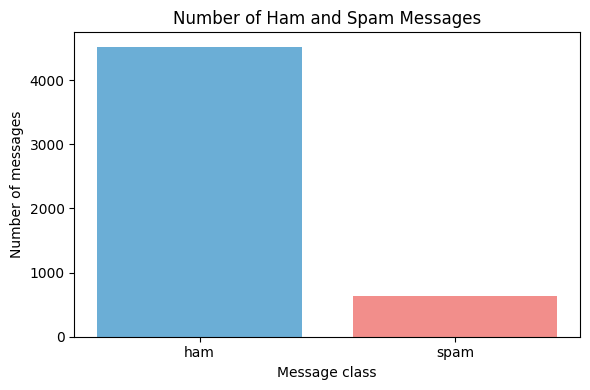

In [5]:
class_summary = sms["label"].value_counts().reindex(["ham", "spam"]).to_frame("messages")
class_summary["percentage"] = 100 * class_summary["messages"] / len(sms)
display(class_summary.round(2))

plt.figure(figsize=(6, 4))
plt.bar(class_summary.index, class_summary["messages"], color=["#6BAED6", "#F28E8B"])
plt.title("Number of Ham and Spam Messages")
plt.xlabel("Message class")
plt.ylabel("Number of messages")
plt.tight_layout()
plt.savefig("../figures/class_balance.png",dpi=300, bbox_inches="tight")
plt.show()

### Interpretation
Ham is the large majority of the messages (about 7 ham for every spam), so the prior strongly favours ham. Accuracy alone can therefore look good even if many spam messages are missed, which is why we also report precision and recall (Question 5).

## 6. Message length by class (Assumption 5)

**Assumption 5** says the model ignores message length: $L_d=\sum_w x_{dw}$ is treated as given and is assumed to have the same distribution in both classes. We measure $L_d$ with the same tokenizer the model uses, so the lengths are exactly the row sums of the count matrix, and compare the two classes with a boxplot and histograms.

,count,mean,median,min,max
label,,,,,
ham,4518,14.66,11.0,0,190
spam,642,25.23,27.0,2,39


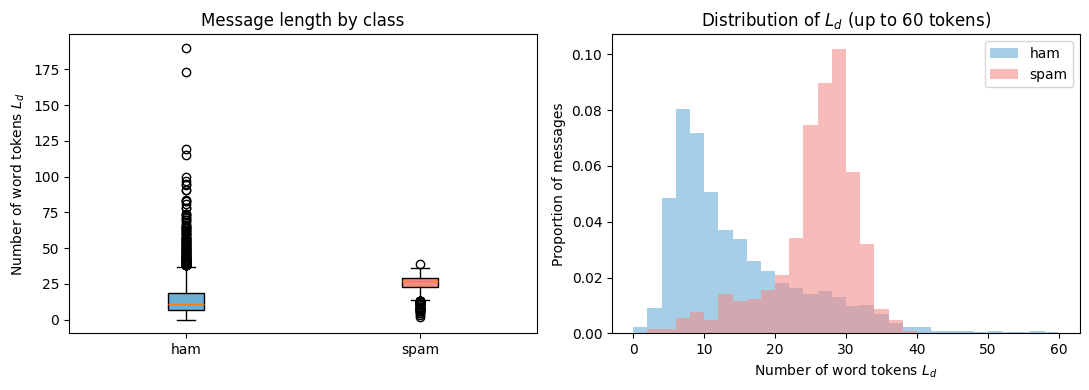

KS statistic = 0.615, p-value = 1.96e-202


In [6]:
sms["L_d"] = sms["message"].apply(lambda m: len(tokenize(m)))   # L_d = sum_w x_dw

length_summary = sms.groupby("label")["L_d"].agg(["count", "mean", "median", "min", "max"]).reindex(["ham", "spam"])
display(length_summary.round(2))

ham_len = sms.loc[sms["label"] == "ham", "L_d"]
spam_len = sms.loc[sms["label"] == "spam", "L_d"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
box = axes[0].boxplot([ham_len, spam_len], patch_artist=True)
axes[0].set_xticks([1, 2], ["ham", "spam"])
for patch, colour in zip(box["boxes"], ["#6BAED6", "#F28E8B"]):
    patch.set_facecolor(colour)
axes[0].set_title("Message length by class")
axes[0].set_ylabel("Number of word tokens $L_d$")

bins = np.arange(0, 61, 2)
axes[1].hist(ham_len, bins=bins, density=True, alpha=0.6, label="ham", color="#6BAED6")
axes[1].hist(spam_len, bins=bins, density=True, alpha=0.6, label="spam", color="#F28E8B")
axes[1].set_title("Distribution of $L_d$ (up to 60 tokens)")
axes[1].set_xlabel("Number of word tokens $L_d$")
axes[1].set_ylabel("Proportion of messages")
axes[1].legend()
plt.tight_layout()
plt.savefig("../figures/message_length_by_class.png",dpi=300, bbox_inches="tight")
plt.show()

# A two-sample Kolmogorov-Smirnov test: are the two length distributions the same?
ks = stats.ks_2samp(ham_len, spam_len)
print(f"KS statistic = {ks.statistic:.3f}, p-value = {ks.pvalue:.2e}")

### Interpretation
Spam messages are clearly longer than ham messages, and the KS test rejects the hypothesis that the two length distributions are equal. So **Assumption 5 does not hold** on this data. This has two consequences we will discuss in the report: the model throws away length as a source of information, and longer messages get more extreme scores because more factors enter the product in Proposition 1.

## 7. Stratified 80/20 split (Assumptions 3 and 4)

We write the split ourselves in NumPy. For each class separately, we shuffle the messages with a fixed seed and put 80% into the training set and 20% into the test set. Splitting within each class keeps the spam share the same in both sets, as required by **Assumption 4 (same distribution for training and test)**.

We then check **Assumption 3** once more: no message text appears in both sets.

In [7]:
def stratified_split(labels, test_fraction, seed):
    # For each class c: shuffle its row indices and send round(test_fraction * n_c) to the test set.
    rng_split = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for c in np.unique(labels):
        idx = np.flatnonzero(labels == c)
        rng_split.shuffle(idx)
        n_test = int(round(test_fraction * len(idx)))
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])
    return np.sort(train_idx), np.sort(test_idx)

classes = np.array(["ham", "spam"])
K = len(classes)
y_all = (sms["label"].to_numpy() == "spam").astype(int)   # ham = 0, spam = 1

train_idx, test_idx = stratified_split(y_all, test_fraction=0.20, seed=0)
train_messages, test_messages = sms.iloc[train_idx], sms.iloc[test_idx]
y_train, y_test = y_all[train_idx], y_all[test_idx]

split_summary = pd.DataFrame({
    "messages": [len(y_train), len(y_test)],
    "spam share": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
display(split_summary.round(4))

overlap = set(train_messages["message"]) & set(test_messages["message"])
print("Message texts in both train and test (Assumption 3):", len(overlap))

,messages,spam share
train,4128,0.1245
test,1032,0.1240


Message texts in both train and test (Assumption 3): 0


## 8. Vocabulary and count matrix $X$

The tokenizer lower-cases each message and keeps runs of letters and digits, so punctuation is removed. The vocabulary $\mathcal{V}$ is built **from the training messages only**, so no information from the test set is used to build the model. Test words that are not in $\mathcal{V}$ are ignored.

Each row of $X$ is one message $\mathbf{x}_d$, each column is one word $w\in\mathcal{V}$, and each entry $x_{dw}$ is a count, exactly as in "Connecting the data to the math" in the report. We also check that $X$ is sparse, which the report uses for the operation counts in Section 5.

In [8]:
training_tokens = train_messages["message"].apply(tokenize)
vocabulary = sorted({w for tokens in training_tokens for w in tokens})
word_to_index = {w: i for i, w in enumerate(vocabulary)}
V_real = len(vocabulary)

def make_count_matrix(messages, index):
    X = np.zeros((len(messages), len(index)), dtype=int)
    for d, message in enumerate(messages):
        for w in tokenize(message):
            if w in index:
                X[d, index[w]] += 1          # x_dw = number of times word w occurs in message d
    return X

X_train = make_count_matrix(train_messages["message"].tolist(), word_to_index)
X_test = make_count_matrix(test_messages["message"].tolist(), word_to_index)

print("|V| =", V_real)
print("X_train shape (n x |V|):", X_train.shape, "  X_test shape:", X_test.shape)
print(f"Non-zero entries in X_train: {np.count_nonzero(X_train)} "
      f"({100 * np.count_nonzero(X_train) / X_train.size:.3f}% of all entries)")
print("Row sums equal L_d:", bool(np.all(X_train.sum(axis=1) ==
      train_messages["message"].apply(lambda m: len(tokenize(m))).to_numpy())))

|V| = 7629
X_train shape (n x |V|): (4128, 7629)   X_test shape: (1032, 7629)
Non-zero entries in X_train: 60180 (0.191% of all entries)
Row sums equal L_d: True


## 9. Zero counts on the real data (Assumption 6)

**Assumption 6** needs $\theta_{cw}>0$ for every class and word. With the unsmoothed MLE $\hat\theta_{cw}=N_{cw}/N_c$ (Proposition 2) this fails for every pair with $N_{cw}=0$. We count how often that happens on the real training data, which shows why Laplace smoothing (Question 3) is not optional for this dataset.

In [9]:
real_params = estimate_parameters(X_train, y_train, K, alpha=1.0)
N_real = real_params["N"]

zero_pairs = (N_real == 0)
print("Class priors pi_hat:", dict(zip(classes, real_params["pi_hat"].round(4))))
print("Tokens per class N_c:", dict(zip(classes, real_params["N_c"])))
for c, name in enumerate(classes):
    print(f"Words with N_cw = 0 in {name}: {zero_pairs[c].sum()} of {V_real} "
          f"({100 * zero_pairs[c].mean():.1f}%)")

test_has_unseen = ((X_test > 0) & zero_pairs[1][None, :]).any(axis=1)
print(f"Test messages containing a word never seen in training spam: {test_has_unseen.sum()} of {len(y_test)}")
print("Without smoothing, all of these would get Pr(x | spam) = 0.")

Class priors pi_hat: {np.str_('ham'): np.float64(0.8755), np.str_('spam'): np.float64(0.1245)}
Tokens per class N_c: {np.str_('ham'): np.int64(53111), np.str_('spam'): np.int64(12991)}
Words with N_cw = 0 in ham: 1613 of 7629 (21.1%)
Words with N_cw = 0 in spam: 5058 of 7629 (66.3%)
Test messages containing a word never seen in training spam: 880 of 1032
Without smoothing, all of these would get Pr(x | spam) = 0.


### Interpretation
Most vocabulary words never appear in the spam training messages, because spam is only about 12% of the data. Without smoothing, a large share of the test messages would get likelihood exactly 0 under spam, so they could never be classified as spam whatever their other words are. This is the real-data version of the zero-count problem in Question 3.

## 10. Preview for Iteration 3: classifying the real test messages

This section is **not required in Iteration 2** (the rules say Python is used here only to explore the data and run the simulation). It applies the algorithm of Section 5 to the real data, so we can see early that the pipeline works. In Iteration 3 these steps will move into `src/methods.py` and be compared with `MultinomialNB`.

In [10]:
S_real = log_scores(X_test, real_params["theta_tilde"], real_params["pi_hat"])   # S = X A^T + 1 b^T
pred_real = S_real.argmax(axis=1)                                                 # step 6

tp, fp, fn, tn = confusion_counts(y_test, pred_real)
display(pd.DataFrame([[tn, fp], [fn, tp]],
                     index=pd.Index(["ham", "spam"], name="Actual"),
                     columns=pd.Index(["ham", "spam"], name="Predicted")))
print(f"Accuracy  = (TP + TN) / m = {(tp + tn) / len(y_test):.4f}")
print(f"Precision = TP / (TP + FP) = {tp / (tp + fp):.4f}")
print(f"Recall    = TP / (TP + FN) = {tp / (tp + fn):.4f}")

Predicted,ham,spam
Actual,,
ham,899,5
spam,16,112


Accuracy  = (TP + TN) / m = 0.9797
Precision = TP / (TP + FP) = 0.9573
Recall    = TP / (TP + FN) = 0.8750


# Part 2 – Simulation with Known Truth

## 11. Generate the simulated messages

We follow the Iteration 2 handout exactly (same seed and same order of random draws), so every member gets the same numbers:

- vocabulary size $\lvert\mathcal{V}\rvert = 20$ and $L = 3$ words per message;
- true word probabilities $\boldsymbol\theta_{\text{ham}}, \boldsymbol\theta_{\text{spam}} \sim \text{Dirichlet}(\mathbf{1})$, which gives two random probability vectors that are non-negative and sum to 1;
- true priors $\pi = (0.8, 0.2)$ and $2{,}000$ messages: first the class $y_d$ is drawn, then the count vector $\mathbf{x}_d \sim \text{Multinomial}(L, \boldsymbol\theta_{y_d})$ (Definition 5);
- the first 1,600 messages are for training and the last 400 for testing.

Because each message draws its $L$ words independently from its class's distribution, **Assumptions 1 and 2 hold exactly** in this simulation. Any difference between estimates and truth is sampling error.

In [11]:
rng = np.random.default_rng(0)
V = 20
theta_true = {0: rng.dirichlet(np.ones(V)),   # ham word probabilities
              1: rng.dirichlet(np.ones(V))}   # spam word probabilities
pi_true = np.array([0.8, 0.2])
n_docs, L = 2000, 3

y_sim = rng.choice(2, size=n_docs, p=pi_true)
X_sim = np.array([rng.multinomial(L, theta_true[c]) for c in y_sim])
Theta_true = np.vstack([theta_true[0], theta_true[1]])      # K x |V|

tr, te = slice(0, 1600), slice(1600, None)
X_sim_train, X_sim_test = X_sim[tr], X_sim[te]
y_sim_train, y_sim_test = y_sim[tr], y_sim[te]

print("Messages:", n_docs, " train:", len(y_sim_train), " test:", len(y_sim_test))
print("Every message has L = 3 tokens:", bool(np.all(X_sim.sum(axis=1) == L)))
print("True theta rows sum to 1:", Theta_true.sum(axis=1))

Messages: 2000  train: 1600  test: 400
Every message has L = 3 tokens: True
True theta rows sum to 1: [1. 1.]


## 12. Estimates and the simulation check table (Proposition 2, Question 3)

We apply steps 1–3 of the algorithm to the 1,600 training messages. The table compares the true values with the estimates. The report's Simulation Check subsection should include this table (the priors plus a few words is enough).

In [12]:
sim = estimate_parameters(X_sim_train, y_sim_train, K=2, alpha=1.0)
theta_hat, theta_tilde = sim["theta_hat"], sim["theta_tilde"]

prior_table = pd.DataFrame({"true": pi_true, "estimate": sim["pi_hat"]}, index=["pi_ham", "pi_spam"])
display(prior_table.round(4))

words_to_show = [0, 2, 9, 11, 16]      # a few words, including word_12 (index 11) which has a zero count
theta_table = pd.DataFrame({
    "word": [f"word_{j+1}" for j in words_to_show],
    "theta_ham (true)": Theta_true[0, words_to_show],
    "theta_hat_ham (MLE)": theta_hat[0, words_to_show],
    "theta_spam (true)": Theta_true[1, words_to_show],
    "theta_hat_spam (MLE)": theta_hat[1, words_to_show],
})
display(theta_table.round(4))

mae = np.abs(theta_hat - Theta_true).mean(axis=1)
print("Mean absolute error of theta_hat (ham, spam):", mae.round(4))
print("Tokens used to estimate each row N_c (ham, spam):", sim["N_c"])

,true,estimate
pi_ham,0.8,0.7894
pi_spam,0.2,0.2106


,word,theta_ham (true),theta_hat_ham (MLE),theta_spam (true),theta_hat_spam (MLE)
0,word_1,0.0251,0.0251,0.0019,0.0010
1,word_3,0.0007,0.0003,0.0535,0.0534
2,word_10,0.2239,0.2214,0.0168,0.0168
3,word_12,0.0000,0.0000,0.0635,0.0564
4,word_17,0.1164,0.1182,0.1521,0.1543


Mean absolute error of theta_hat (ham, spam): [0.0013 0.0037]
Tokens used to estimate each row N_c (ham, spam): [3789 1011]


### Interpretation
The estimates are close to the true values, as Proposition 2 predicts. The spam row is less accurate than the ham row because spam has only about 20% of the training messages, so its row is estimated from roughly a quarter as many tokens $N_c$. The standard error of a frequency estimate shrinks like $1/\sqrt{N_c}$, so fewer tokens means larger errors.

## 13. Check of Proposition 1 (the posterior)

Proposition 1 gives the posterior
$$\Pr(Y=c\mid \mathbf{x}) = \frac{\pi_c\prod_w\theta_{cw}^{x_w}}{\sum_{c'}\pi_{c'}\prod_w\theta_{c'w}^{x_w}}.$$

We check it three ways:

1. **Count form.** $\prod_{j=1}^{L}\theta_{cw_j}=\prod_w\theta_{cw}^{x_w}$ (step 7 of the proof) for an example word sequence.
2. **It is a probability.** The posteriors are in $[0,1]$ and sum to 1 over the two classes.
3. **It matches the data.** A posterior is a statement about frequencies: among messages that get posterior $p$, a fraction of about $p$ should really be spam. We compute the formula posterior (with the true parameters) for all 2,000 simulated messages, group them into posterior ranges, and compare the average posterior in each range with the observed fraction of spam.

In [13]:
# (1) Count form: the sequence (word_3, word_8, word_3) has x_3 = 2, x_8 = 1
sequence = [2, 7, 2]
x_example = np.bincount(sequence, minlength=V)
for c, name in enumerate(classes):
    product_over_positions = np.prod(Theta_true[c, sequence])
    product_over_words = np.prod(Theta_true[c] ** x_example)
    print(f"{name}: prod_j theta_(c,w_j) = {product_over_positions:.6e}, "
          f"prod_w theta_cw^x_w = {product_over_words:.6e}")

# (2) Posteriors from the formula (true parameters) for every simulated message
post_true = posteriors_from_scores(log_scores(X_sim, Theta_true, pi_true))
print("\nPosteriors in [0, 1]:", bool(np.all((post_true >= 0) & (post_true <= 1))))
print("Max |sum_c Pr(c | x) - 1|:", np.abs(post_true.sum(axis=1) - 1).max())

# (3) Calibration: group messages by their formula posterior and compare with the observed spam fraction
bins = [0, 0.1, 0.3, 0.7, 0.9, 1.0]
calib = pd.DataFrame({"posterior_spam": post_true[:, 1], "spam": y_sim})
calib["posterior range"] = pd.cut(calib["posterior_spam"], bins=bins, include_lowest=True)
calib_table = calib.groupby("posterior range", observed=True).agg(
    messages=("spam", "size"),
    mean_formula_posterior=("posterior_spam", "mean"),
    observed_spam_fraction=("spam", "mean"))
calib_table["std_error"] = np.sqrt(calib_table["mean_formula_posterior"]
                                   * (1 - calib_table["mean_formula_posterior"]) / calib_table["messages"])
calib_table["difference_in_SE"] = ((calib_table["observed_spam_fraction"] - calib_table["mean_formula_posterior"])
                                   / calib_table["std_error"])
display(calib_table.round(3))

ham: prod_j theta_(c,w_j) = 1.496037e-08, prod_w theta_cw^x_w = 1.496037e-08
spam: prod_j theta_(c,w_j) = 2.752456e-04, prod_w theta_cw^x_w = 2.752456e-04

Posteriors in [0, 1]: True
Max |sum_c Pr(c | x) - 1|: 2.220446049250313e-16


,messages,mean_formula_posterior,observed_spam_fraction,std_error,difference_in_SE
posterior range,,,,,
"(-0.001, 0.1]",1342,0.018,0.022,0.004,0.852
"(0.1, 0.3]",217,0.199,0.203,0.027,0.154
"(0.3, 0.7]",160,0.492,0.462,0.040,-0.734
"(0.7, 0.9]",79,0.809,0.823,0.044,0.311
"(0.9, 1.0]",202,0.983,0.985,0.009,0.218


### Interpretation
The two forms of the product are equal and the posteriors are valid probabilities. In every posterior range, the observed fraction of spam is close to the average posterior from the Proposition 1 formula, within about 2 standard errors (the last column), which is the size of difference expected from sampling alone. This is a direct numerical check that Bayes' theorem with conditional independence gives the correct posterior when Assumptions 1–2 hold.

## 14. Check of Proposition 2 (maximum likelihood)

Proposition 2 says $\hat\theta_{cw}=N_{cw}/N_c$ **maximizes** the log-likelihood $\sum_w N_{cw}\log\theta_{cw}$ subject to $\sum_w\theta_{cw}=1$. We check three things:

1. **Lagrange condition** (proof steps 5–6): for every word with $N_{cw}>0$, $N_{cw}/\hat\theta_{cw}=\lambda$ is the same number, and that number is $N_c$.
2. **It is the maximum** (proof step 7): no other probability vector gives a higher log-likelihood. We try 10,000 random probability vectors.
3. **Priors**: $\hat\pi_c=n_c/n$ sums to 1.

In [14]:
rng_check = np.random.default_rng(1)       # separate generator, so the simulation above is unchanged
N_sim, N_c_sim = sim["N"], sim["N_c"]

for c, name in enumerate(classes):
    seen = N_sim[c] > 0
    lam = N_sim[c, seen] / theta_hat[c, seen]          # N_cw / theta_hat_cw = lambda
    print(f"{name}: lambda ranges from {lam.min():.6f} to {lam.max():.6f};  N_c = {N_c_sim[c]}")

def log_lik(theta_row, counts):
    with np.errstate(divide="ignore", invalid="ignore"):
        terms = np.where(counts > 0, counts * np.log(theta_row), 0.0)
    return terms.sum(axis=-1)

for c, name in enumerate(classes):
    best = log_lik(theta_hat[c], N_sim[c])
    alternatives = rng_check.dirichlet(np.ones(V), size=10_000)
    alt = log_lik(alternatives, N_sim[c])
    print(f"{name}: log-likelihood at theta_hat = {best:.3f}; best of 10,000 alternatives = {alt.max():.3f}; "
          f"theta_hat is higher: {bool(best > alt.max())}")

print("pi_hat =", sim["pi_hat"], " sum =", sim["pi_hat"].sum())

ham: lambda ranges from 3789.000000 to 3789.000000;  N_c = 3789
spam: lambda ranges from 1011.000000 to 1011.000000;  N_c = 1011
ham: log-likelihood at theta_hat = -9357.204; best of 10,000 alternatives = -10124.044; theta_hat is higher: True
spam: log-likelihood at theta_hat = -2730.893; best of 10,000 alternatives = -2881.894; theta_hat is higher: True
pi_hat = [0.789375 0.210625]  sum = 1.0


## 15. Check of Proposition 3 (Question 3: zero counts and Laplace smoothing)

Question 3 shows that a word with $N_{cw}=0$ gives $\hat\theta_{cw}=0$, so a new message containing it gets likelihood $0$ and log-likelihood $-\infty$. Laplace smoothing $\tilde\theta_{cw}=(N_{cw}+\alpha)/(N_c+\alpha\lvert\mathcal{V}\rvert)$ fixes this, and the proof shows $\tilde\theta_{cw}>0$ and $\sum_w\tilde\theta_{cw}=1$.

In [15]:
zero = np.argwhere(N_sim == 0)
print("(class, word) pairs with N_cw = 0:", [(classes[c], f"word_{w+1}") for c, w in zero])

c0, w0 = zero[0]
x_new = np.zeros(V, dtype=int); x_new[w0] = 1        # a new message containing that word
with np.errstate(divide="ignore"):
    print(f"\nUnsmoothed: theta_hat = {theta_hat[c0, w0]}, log-score for {classes[c0]} = "
          f"{log_scores(x_new[None, :], theta_hat, sim['pi_hat'])[0, c0]}")
print(f"Smoothed:   theta_tilde = {theta_tilde[c0, w0]:.6f}, log-score for {classes[c0]} = "
      f"{log_scores(x_new[None, :], theta_tilde, sim['pi_hat'])[0, c0]:.4f}")
print(f"Formula: (N_cw + 1) / (N_c + |V|) = (0 + 1) / ({N_c_sim[c0]} + {V}) = {1 / (N_c_sim[c0] + V):.6f}")

print("\nAll theta_tilde > 0:", bool(np.all(theta_tilde > 0)))
print("Rows of theta_tilde sum to 1:", theta_tilde.sum(axis=1))

(class, word) pairs with N_cw = 0: [(np.str_('ham'), 'word_12')]

Unsmoothed: theta_hat = 0.0, log-score for ham = -inf
Smoothed:   theta_tilde = 0.000263, log-score for ham = -8.4816
Formula: (N_cw + 1) / (N_c + |V|) = (0 + 1) / (3789 + 20) = 0.000263

All theta_tilde > 0: True
Rows of theta_tilde sum to 1: [1. 1.]


## 16. Check of Proposition 4 (logarithms and the linear decision rule)

Proposition 4 makes four claims we can check with numbers:

1. **(b) Same decision.** The class with the largest product score $s_c=\pi_c\prod_w\theta_{cw}^{x_w}$ is the class with the largest log-score.
2. **(c) Linear form.** The matrix formula $S=XA^\top+\mathbf{1}\mathbf{b}^\top$ equals the score computed message by message.
3. **Decision rule.** $(\mathbf{a}_{\text{spam}}-\mathbf{a}_{\text{ham}})^\top\mathbf{x}+(b_{\text{spam}}-b_{\text{ham}})$ equals the log posterior odds $\log\frac{\Pr(\text{spam}\mid\mathbf{x})}{\Pr(\text{ham}\mid\mathbf{x})}$, and predicting spam when it is positive gives the same predictions.
4. **Underflow.** A product of 500 probabilities of $0.01$ rounds to $0$ in floating point, but $500\log 0.01\approx-2302.6$ is fine.

In [16]:
pi_hat_sim = sim["pi_hat"]
S = log_scores(X_sim_test, theta_tilde, pi_hat_sim)          # S = X A^T + 1 b^T
pred_log = S.argmax(axis=1)

# (1) product scores s_c = pi_c * prod_w theta_cw^x_w
s_product = np.column_stack([pi_hat_sim[c] * np.prod(theta_tilde[c] ** X_sim_test, axis=1) for c in (0, 1)])
pred_product = s_product.argmax(axis=1)
print("(1) Same predictions from products and logs:", bool(np.array_equal(pred_log, pred_product)))

# (2) matrix formula vs. message-by-message sum log pi_c + sum_w x_w log theta_cw
S_loop = np.array([[np.log(pi_hat_sim[c]) + np.sum(x * np.log(theta_tilde[c])) for c in (0, 1)]
                   for x in X_sim_test])
print("(2) Max |S_matrix - S_loop|:", np.abs(S - S_loop).max())

# (3) linear decision rule = log posterior odds
weights = np.log(theta_tilde[1]) - np.log(theta_tilde[0])     # a_spam - a_ham, one weight per word
intercept = np.log(pi_hat_sim[1]) - np.log(pi_hat_sim[0])     # b_spam - b_ham = log prior odds
linear_rule = X_sim_test @ weights + intercept
post = posteriors_from_scores(S)                              # step 7
log_odds = np.log(post[:, 1] / post[:, 0])
print("(3) Max |linear rule - log posterior odds|:", np.abs(linear_rule - log_odds).max())
print("    Same predictions as argmax:", bool(np.array_equal((linear_rule > 0).astype(int), pred_log)))

weight_table = pd.DataFrame({"word": [f"word_{j+1}" for j in range(V)], "weight log(theta_spam/theta_ham)": weights})
print("\nMost 'spammy' and most 'hammy' words:")
display(pd.concat([weight_table.nlargest(3, weight_table.columns[1]),
                   weight_table.nsmallest(3, weight_table.columns[1])]).round(3))

# (4) underflow
p = np.full(500, 0.01)
print(f"(4) Product of 500 x 0.01 = {np.prod(p)}   Sum of logs = {np.sum(np.log(p)):.4f}")

(1) Same predictions from products and logs: True
(2) Max |S_matrix - S_loop|: 3.552713678800501e-15
(3) Max |linear rule - log posterior odds|: 3.552713678800501e-15
    Same predictions as argmax: True

Most 'spammy' and most 'hammy' words:


,word,weight log(theta_spam/theta_ham)
11,word_12,5.367
2,word_3,4.621
3,word_4,4.079
0,word_1,-2.564
9,word_10,-2.536
10,word_11,-2.322


(4) Product of 500 x 0.01 = 0.0   Sum of logs = -2302.5851


## 17. Check of Proposition 5 (Question 5: precision and recall as conditional probabilities)

Spam is the positive class. Question 5 shows that precision $=\Pr(S\mid\hat S)$ and recall $=\Pr(\hat S\mid S)$. With equally likely test messages, a conditional probability is computed by **counting inside the condition** (Lecture 8). So we compute each quantity twice: once by restricting to the condition and counting, and once with the TP/FP/FN formulas.

In [17]:
tp, fp, fn, tn = confusion_counts(y_sim_test, pred_log)
display(pd.DataFrame([[tn, fp], [fn, tp]],
                     index=pd.Index(["ham", "spam"], name="Actual"),
                     columns=pd.Index(["ham", "spam"], name="Predicted")))

precision_formula = tp / (tp + fp)
recall_formula = tp / (tp + fn)
precision_counting = np.mean(y_sim_test[pred_log == 1] == 1)     # among predicted spam, fraction actually spam
recall_counting = np.mean(pred_log[y_sim_test == 1] == 1)        # among actual spam, fraction predicted spam

print(f"Precision: Pr(S | S_hat) by counting = {precision_counting:.4f},  TP/(TP+FP) = {precision_formula:.4f}")
print(f"Recall:    Pr(S_hat | S) by counting = {recall_counting:.4f},  TP/(TP+FN) = {recall_formula:.4f}")
print(f"Accuracy:  (TP+TN)/m = {(tp + tn) / len(y_sim_test):.4f}")

Predicted,ham,spam
Actual,,
ham,311,15
spam,21,53


Precision: Pr(S | S_hat) by counting = 0.7794,  TP/(TP+FP) = 0.7794
Recall:    Pr(S_hat | S) by counting = 0.7162,  TP/(TP+FN) = 0.7162
Accuracy:  (TP+TN)/m = 0.9100


## 18. Similarity experiment: making the two word distributions more similar

As the handout asks, we move both true probability vectors toward their average:
$$\boldsymbol\theta_c^{(t)} = (1-t)\,\boldsymbol\theta_c + t\,\bar{\boldsymbol\theta},\qquad \bar{\boldsymbol\theta}=\tfrac12(\boldsymbol\theta_{\text{ham}}+\boldsymbol\theta_{\text{spam}}),\quad t\in[0,1].$$
Each $\boldsymbol\theta_c^{(t)}$ is still a probability vector, because it is a convex combination of probability vectors. At $t=1$ the two classes have the same word distribution, so by Proposition 1 the posterior equals the prior for every message, and the classifier can only use the prior.

We report balanced accuracy, the average of ham recall and spam recall, because it is not inflated by the large ham class.

,t (mixing level),||theta_ham - theta_spam||_2,accuracy,balanced accuracy,ham recall,spam recall
0,0.00,0.2965,0.9475,0.8725,0.9879,0.7571
1,0.25,0.2224,0.8750,0.7216,0.9576,0.4857
2,0.50,0.1483,0.8525,0.5955,0.9909,0.2000
3,0.75,0.0741,0.8275,0.5240,0.9909,0.0571
4,1.00,0.0000,0.8250,0.5000,1.0000,0.0000


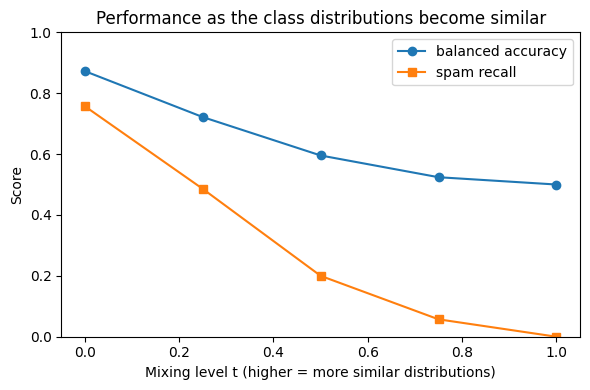

In [18]:
theta_bar = (Theta_true[0] + Theta_true[1]) / 2
rows = []
for t in [0.0, 0.25, 0.50, 0.75, 1.0]:
    Theta_t = (1 - t) * Theta_true + t * theta_bar
    rng_t = np.random.default_rng(1000)                      # same seed at every level
    y_t = rng_t.choice(2, size=n_docs, p=pi_true)
    X_t = np.array([rng_t.multinomial(L, Theta_t[c]) for c in y_t])
    est = estimate_parameters(X_t[tr], y_t[tr], K=2, alpha=1.0)
    pred_t = log_scores(X_t[te], est["theta_tilde"], est["pi_hat"]).argmax(axis=1)
    tp_t, fp_t, fn_t, tn_t = confusion_counts(y_t[te], pred_t)
    ham_recall, spam_recall = tn_t / (tn_t + fp_t), tp_t / (tp_t + fn_t)
    rows.append({"t (mixing level)": t,
                 "||theta_ham - theta_spam||_2": np.linalg.norm(Theta_t[0] - Theta_t[1]),
                 "accuracy": np.mean(pred_t == y_t[te]),
                 "balanced accuracy": (ham_recall + spam_recall) / 2,
                 "ham recall": ham_recall, "spam recall": spam_recall})

similarity = pd.DataFrame(rows)
display(similarity.round(4))

plt.figure(figsize=(6, 4))
plt.plot(similarity["t (mixing level)"], similarity["balanced accuracy"], marker="o", label="balanced accuracy")
plt.plot(similarity["t (mixing level)"], similarity["spam recall"], marker="s", label="spam recall")
plt.xlabel("Mixing level t (higher = more similar distributions)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Performance as the class distributions become similar")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/class_similarity_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretation
As $t$ grows, the distance between the two word distributions shrinks and balanced accuracy falls toward 0.5. At $t=1$ the likelihoods are identical for both classes, so by Proposition 1 the posterior equals the prior. Since $\hat\pi_{\text{ham}}\approx0.8>0.5$, the model predicts ham for every message: ham recall is 1, spam recall is 0, and ordinary accuracy still looks high (about 0.8) only because ham is common. This shows that the classifier's power comes entirely from the difference between $\boldsymbol\theta_{\text{ham}}$ and $\boldsymbol\theta_{\text{spam}}$.

## 19. Summary: what each check confirms (for the report's Simulation Check)

| Result in the report | Check in this notebook | Section |
|---|---|---|
| Proposition 1 (posterior) | count form of the product; posteriors sum to 1; observed spam fraction matches the formula posterior in every range | 13 |
| Proposition 2 (MLE) | $\hat\theta\approx\theta$ (table); $N_{cw}/\hat\theta_{cw}=\lambda=N_c$; $\hat\theta$ beats 10,000 random alternatives | 12, 14 |
| Proposition 3 (smoothing) | zero count gives $\log 0=-\infty$; $\tilde\theta>0$; rows sum to 1 | 15 |
| Proposition 4 (logs, linear rule) | same predictions from products and logs; $S=XA^\top+\mathbf{1}\mathbf{b}^\top$; linear rule = log posterior odds; underflow demo | 16 |
| Proposition 5 (precision, recall) | counting inside the condition equals TP/(TP+FP) and TP/(TP+FN) | 17 |
| Assumption 3 | duplicates removed; no text in both train and test | 4, 7 |
| Assumption 4 | stratified split keeps the same spam share | 7 |
| Assumption 5 | spam is longer than ham (KS test): the assumption fails on real data | 6 |
| Assumption 6 | many zero counts on real data, so smoothing is needed | 9 |